# Exploratory Data Analysis (EDA) - Sales Data

**Goal:** understand the business *before* writing KPI/driver code. Every chart below answers one business question
and is followed by what we learn from it. Run the cells top to bottom (`Kernel > Restart & Run All`).

In [1]:
import sys
sys.path.insert(0, "..")                       # so we can import our src/ package
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from src.data_ingestion import load_dataset
from src.data_cleaning import clean_data
from src.kpi_calculation import monthly_summary

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
lakh = lambda x, _=None: f"{x/1e5:,.0f}L"       # axis helper: 1,200,000 -> 12L (L = lakh)

raw = load_dataset("../data/sales_data.xlsx")
df, report = clean_data(raw)
print(f"Raw rows: {len(raw):,}  ->  clean rows: {len(df):,}")
pd.Series(report["issues"], name="count").to_frame()

Raw rows: 12,149  ->  clean rows: 11,785


,count
invalid_dates_removed,47
text_values_standardized,975
rows_missing_critical_fields,105
exact_duplicates_removed,179
region_repaired_from_state,117
category_repaired_from_product,95
discount_missing_filled,119
discount_percent_converted,35
invalid_quantity_removed,35
invalid_sales_removed,22


## 1. Data overview
Shape, types, ranges. This is the first sanity check after cleaning.

In [2]:
print("Date range :", df["Date"].min().date(), "to", df["Date"].max().date())
print("Orders     :", df["Order_ID"].nunique(), "| Customers:", df["Customer_ID"].nunique(),
      "| Products:", df["Product"].nunique(), "| Regions:", df["Region"].nunique())
df[["Quantity", "Sales", "Cost", "Discount", "Profit"]].describe().round(2)

Date range : 2024-01-01 to 2026-09-30
Orders     : 11785 | Customers: 1500 | Products: 11 | Regions: 4


,Quantity,Sales,Cost,Discount,Profit
count,11785.00,11785.00,11785.00,11785.00,11785.00
mean,1.80,19775.09,15877.21,0.05,3897.88
std,0.97,26293.30,21903.84,0.06,4925.08
min,1.00,305.30,168.35,0.00,-3771.31
25%,1.00,2772.14,1628.56,0.00,995.16
50%,2.00,9783.69,6676.73,0.05,2338.45
75%,2.00,22467.37,17893.75,0.10,4567.65
max,7.00,228077.51,176227.21,0.20,59793.63


## 2. Monthly performance
**Question:** is the business growing, and is there seasonality?

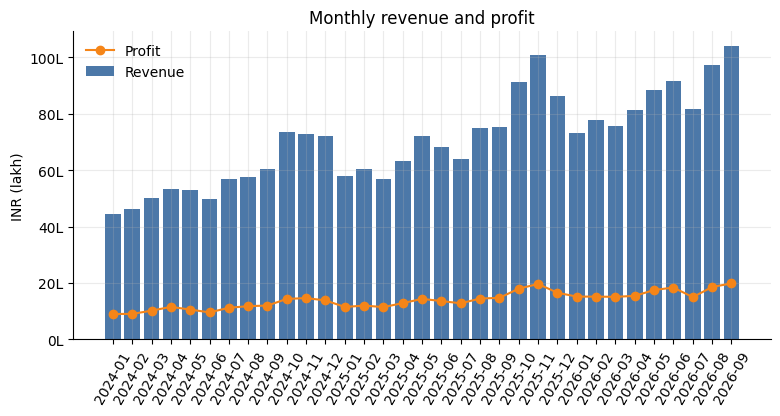

In [3]:
m = monthly_summary(df)
m["Month"] = m["Month"].astype(str)
fig, ax = plt.subplots()
ax.bar(m["Month"], m["Revenue"], color="#4C78A8", label="Revenue")
ax.plot(m["Month"], m["Profit"], color="#F58518", marker="o", label="Profit")
ax.yaxis.set_major_formatter(lakh); ax.set_ylabel("INR (lakh)"); ax.set_title("Monthly revenue and profit")
ax.tick_params(axis="x", rotation=60); ax.legend(frameon=False); plt.show()

**Read it like an analyst:** look at the slope (growth), the Oct-Nov bump (festival season) and whether profit moves in step with revenue. If profit lags revenue, margin is shrinking - that is exactly what the KPI/insight engine will test later.

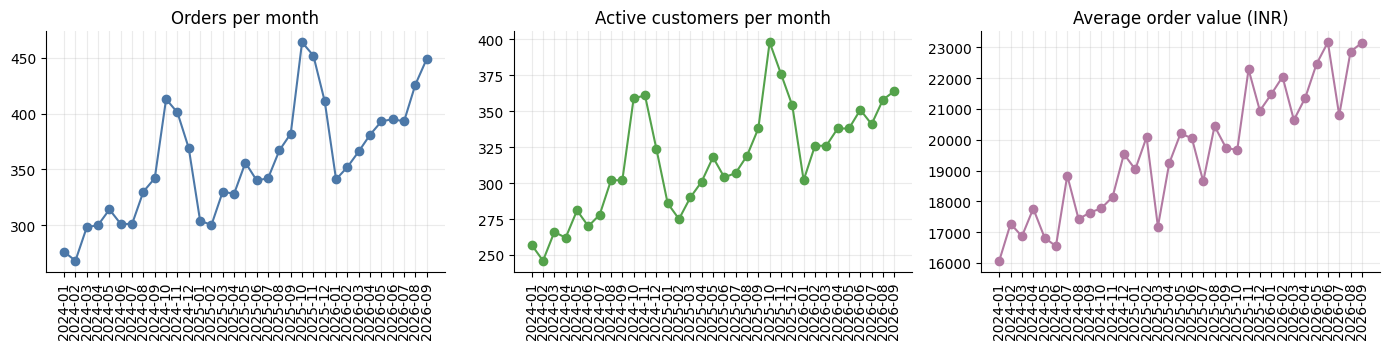

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, title, color in zip(axes, ["Orders", "Customers", "AOV"], ["Orders per month", "Active customers per month", "Average order value (INR)"], ["#4C78A8", "#54A24B", "#B279A2"]):
    ax.plot(m["Month"], m[col], marker="o", color=color); ax.set_title(title); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

**Why three charts?** Revenue = Orders x Average Order Value. Splitting it tells us whether growth comes from *more orders* or *bigger baskets*.

## 3. Regional performance
**Question:** which regions make money, and which make money *efficiently*?

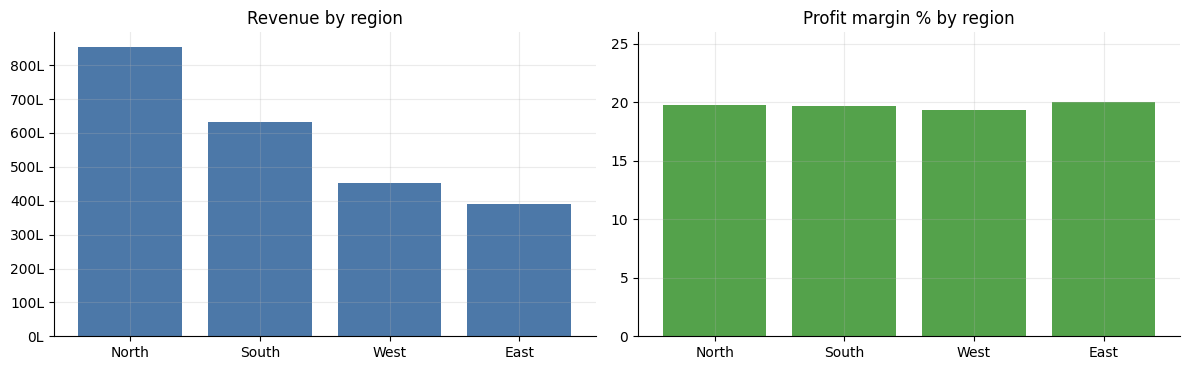

,Revenue,Profit,Orders,Margin_%
Region,,,,
North,85434558.0,16885034.2,4291,19.8
South,63303965.2,12482378.1,3195,19.7
West,45145251.0,8736882.6,2364,19.4
East,39165708.0,7832262.8,1935,20.0


In [5]:
reg = df.groupby("Region").agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order_ID", "nunique"))
reg["Margin_%"] = reg["Profit"] / reg["Revenue"] * 100
reg = reg.sort_values("Revenue", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(reg.index, reg["Revenue"], color="#4C78A8"); axes[0].yaxis.set_major_formatter(lakh); axes[0].set_title("Revenue by region")
axes[1].bar(reg.index, reg["Margin_%"], color="#54A24B"); axes[1].set_title("Profit margin % by region"); axes[1].set_ylim(0, reg["Margin_%"].max() * 1.3)
plt.tight_layout(); plt.show()
reg.round(1)

## 4. Category and product performance
**Question:** what do we sell, and what is actually profitable? (Revenue rank and profit rank are often different.)

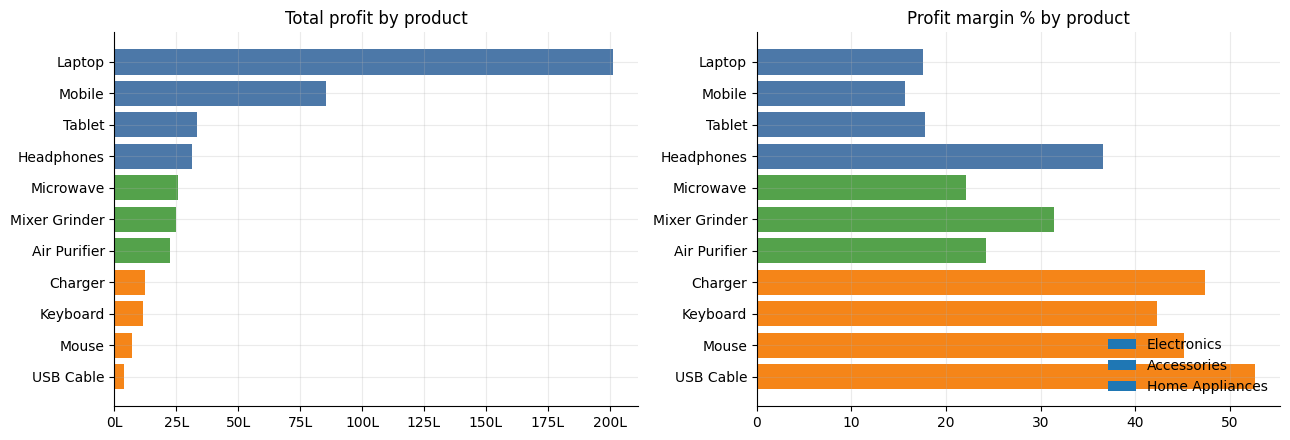

In [6]:
prod = df.groupby(["Product_Category", "Product"]).agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"), Qty=("Quantity", "sum")).reset_index()
prod["Margin_%"] = prod["Profit"] / prod["Revenue"] * 100
prod = prod.sort_values("Profit")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = prod["Product_Category"].map({"Electronics": "#4C78A8", "Accessories": "#F58518", "Home Appliances": "#54A24B"})
axes[0].barh(prod["Product"], prod["Profit"], color=colors); axes[0].xaxis.set_major_formatter(lakh); axes[0].set_title("Total profit by product")
axes[1].barh(prod["Product"], prod["Margin_%"], color=colors); axes[1].set_title("Profit margin % by product")
for c, l in {"#4C78A8": "Electronics", "#F58518": "Accessories", "#54A24B": "Home Appliances"}.items():
    axes[1].barh([], [], color=c, label=l)
axes[1].legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

In [7]:
cat = df.groupby("Product_Category").agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"))
cat["Revenue_share_%"] = cat["Revenue"] / cat["Revenue"].sum() * 100
cat["Margin_%"] = cat["Profit"] / cat["Revenue"] * 100
print("Top 5 products by profit"); display(prod.sort_values("Profit", ascending=False).head(5).round(1))
print("Bottom 5 products by profit"); display(prod.sort_values("Profit").head(5).round(1))
cat.sort_values("Revenue", ascending=False).round(1)

Top 5 products by profit


,Product_Category,Product,Revenue,Profit,Qty,Margin_%
5,Electronics,Laptop,114550044.9,20117866.9,2203,17.6
6,Electronics,Mobile,54632267.8,8566039.2,2617,15.7
7,Electronics,Tablet,18857938.4,3347892.8,1104,17.8
4,Electronics,Headphones,8606869.6,3145265.7,2599,36.5
9,Home Appliances,Microwave,11605144.9,2563097.3,1360,22.1


Bottom 5 products by profit


,Product_Category,Product,Revenue,Profit,Qty,Margin_%
3,Accessories,USB Cable,702880.4,370117.9,1852,52.7
2,Accessories,Mouse,1544871.2,697801.9,2035,45.2
1,Accessories,Keyboard,2779424.2,1175810.4,1944,42.3
0,Accessories,Charger,2578127.8,1221534.9,2261,47.4
8,Home Appliances,Air Purifier,9248066.2,2240398.4,810,24.2


,Revenue,Profit,Revenue_share_%,Margin_%
Product_Category,,,,
Electronics,196647120.6,35177064.6,84.4,17.9
Home Appliances,28797058.1,7294228.0,12.4,25.3
Accessories,7605303.6,3465265.1,3.3,45.6


## 5. Discounts and margin
**Question:** do bigger discounts hurt profitability? (A relationship worth monitoring, not proof of cause.)

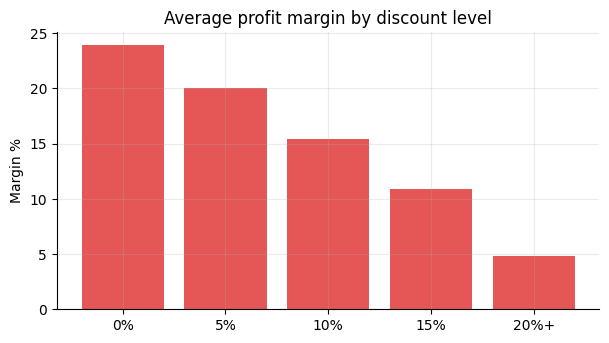

,Orders,Revenue,Profit,Margin_%
Discount,,,,
0%,5253,107529121.4,25698316.4,23.9
5%,2910,57997066.2,11624347.0,20.0
10%,2123,39999814.5,6158736.4,15.4
15%,1023,18590653.5,2024122.7,10.9
20%+,476,8932826.6,431035.2,4.8


In [8]:
bins = pd.cut(df["Discount"], [-0.001, 0, 0.05, 0.10, 0.15, 1], labels=["0%", "5%", "10%", "15%", "20%+"])
disc = df.groupby(bins, observed=True).agg(Orders=("Order_ID", "count"), Revenue=("Sales", "sum"), Profit=("Profit", "sum"))
disc["Margin_%"] = disc["Profit"] / disc["Revenue"] * 100
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.bar(disc.index.astype(str), disc["Margin_%"], color="#E45756")
ax.set_title("Average profit margin by discount level"); ax.set_ylabel("Margin %"); plt.show()
disc.round(1)

## 6. Customer segments

In [9]:
seg = df.groupby("Customer_Segment").agg(Revenue=("Sales", "sum"), Orders=("Order_ID", "nunique"), Customers=("Customer_ID", "nunique"))
seg["AOV"] = seg["Revenue"] / seg["Orders"]
seg["Revenue_per_customer"] = seg["Revenue"] / seg["Customers"]
seg.round(0)

,Revenue,Orders,Customers,AOV,Revenue_per_customer
Customer_Segment,,,,,
Consumer,138894495.0,6934,904,20031.0,153644.0
Corporate,55866707.0,2832,367,19727.0,152225.0
Small Business,36080321.0,1903,229,18960.0,157556.0
Unknown,2207960.0,116,106,19034.0,20830.0


## 7. Year-over-year view
**Question:** is 2026 beating 2025 in the same months? (Removes seasonality from the comparison.)

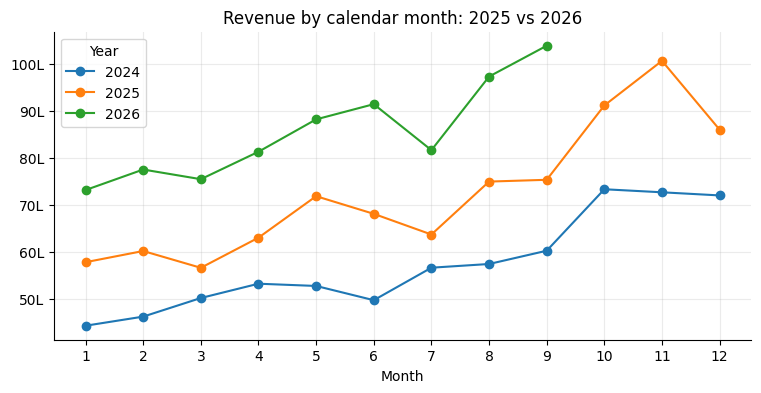

In [10]:
d = df.assign(Year=df["Date"].dt.year, Mon=df["Date"].dt.month)
pv = d.pivot_table(index="Mon", columns="Year", values="Sales", aggfunc="sum")
fig, ax = plt.subplots(); pv.plot(ax=ax, marker="o"); ax.yaxis.set_major_formatter(lakh)
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_title("Revenue by calendar month: 2025 vs 2026"); plt.show()

## 8. Order value distribution and outliers
**Question:** are there suspicious values? (The cleaning step flags/removes extreme data-entry errors.)

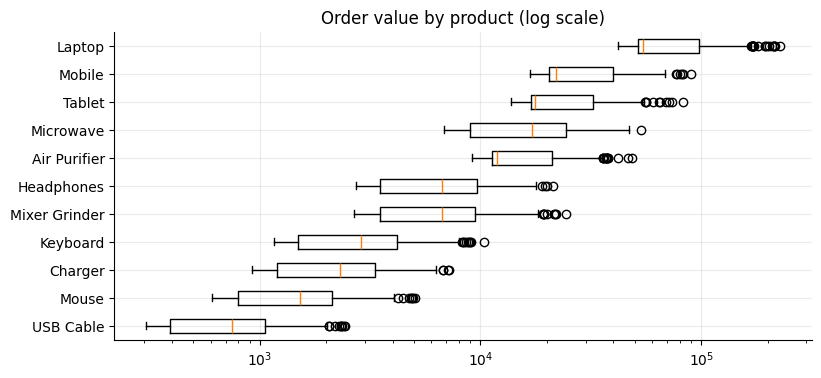

Outliers flagged (kept for analysis): 5


In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
order = df.groupby("Product")["Sales"].median().sort_values().index
ax.boxplot([df.loc[df["Product"] == p, "Sales"] for p in order], labels=order, vert=False, showfliers=True)
ax.set_xscale("log"); ax.set_title("Order value by product (log scale)"); plt.show()
print("Outliers flagged (kept for analysis):", int(df["Is_Outlier"].sum()))

## 7b. Sales channel and payment method
**Question:** how do customers buy and pay, and is the mix shifting? (A shift in mix is often an early sign of a change in customer behaviour.)

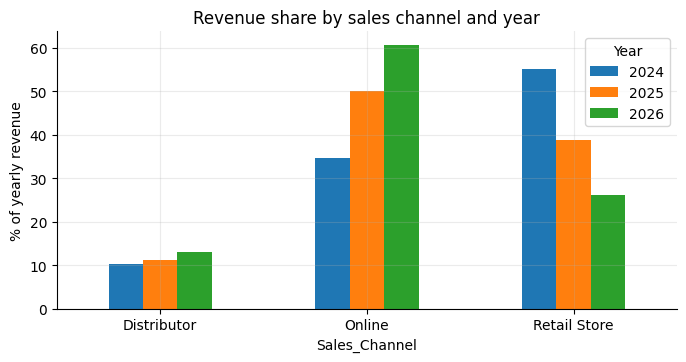

Year           2024  2025  2026
Sales_Channel                  
Distributor    10.4  11.2  13.1
Online         34.6  50.1  60.7
Retail Store   55.1  38.7  26.2


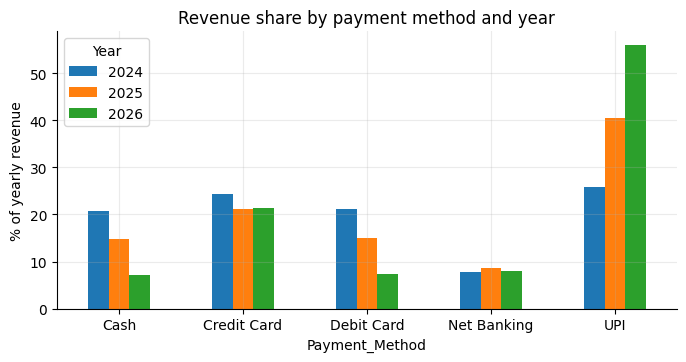

Year            2024  2025  2026
Payment_Method                  
Cash            20.7  14.8   7.2
Credit Card     24.5  21.2  21.3
Debit Card      21.2  14.9   7.3
Net Banking      7.8   8.5   8.0
UPI             25.9  40.6  56.1


In [12]:
for col, color in (("Sales_Channel", "#4C78A8"), ("Payment_Method", "#54A24B")):
    if col not in df.columns:
        continue
    share = (df.assign(Year=df["Date"].dt.year).pivot_table(index=col, columns="Year", values="Sales", aggfunc="sum"))
    share = share / share.sum() * 100
    ax = share.plot(kind="bar", figsize=(8, 3.6), rot=0)
    ax.set_ylabel("% of yearly revenue"); ax.set_title(f"Revenue share by {col.replace('_', ' ').lower()} and year"); plt.show()
    print(share.round(1))

## 9. Key takeaways (generated from the data)

In [13]:
best = m.loc[m["Revenue"].idxmax()]
top_reg = reg["Revenue"].idxmax(); top_prod = prod.sort_values("Profit").iloc[-1]; low_margin = prod.sort_values("Margin_%").iloc[0]
print(f"- Best month: {best['Month']} with INR {best['Revenue']:,.0f} revenue")
print(f"- Largest region: {top_reg} ({reg.loc[top_reg, 'Revenue'] / reg['Revenue'].sum():.0%} of revenue)")
print(f"- Most profitable product: {top_prod['Product']} (INR {top_prod['Profit']:,.0f} profit)")
print(f"- Lowest-margin product: {low_margin['Product']} ({low_margin['Margin_%']:.1f}% margin)")
print(f"- Margin at 0% discount: {disc['Margin_%'].iloc[0]:.1f}%  vs  20%+ discount: {disc['Margin_%'].iloc[-1]:.1f}%")

- Best month: 2026-09 with INR 10,395,191 revenue
- Largest region: North (37% of revenue)
- Most profitable product: Laptop (INR 20,117,867 profit)
- Lowest-margin product: Mobile (15.7% margin)
- Margin at 0% discount: 23.9%  vs  20%+ discount: 4.8%
